# Proyecto 2 — Modelos: Línea Base (Metadatos) · Evaluación · Visualizaciones
## RSNA 2024 Lumbar Spine Degenerative Classification

Dataset: tabular — 48 692 filas (condition × level × series_description × instance_number × x × y + severidad)  
Objetivo: (C.0, C.1) Entrenar la línea base «solo metadatos» (Random Forest + Gradient Boosting), evaluar con las métricas del plan, generar resultados.json y las gráficas estáticas.  
Semilla global:*42 · Split: por study_id (70 / 15 / 15)

Este notebook no usa imágenes DICOM. La línea de imagen (CNN, etc.) se ejecuta en Kaggle.

## 0. Importaciones y configuración

In [1]:
import pandas as pd
import numpy as np
import json, time, os, warnings
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    f1_score, balanced_accuracy_score, recall_score, precision_score,
    confusion_matrix, cohen_kappa_score, log_loss, classification_report
)
import joblib

warnings.filterwarnings("ignore")
np.random.seed(42)

# ── Paths ──
ROOT   = Path(".")
PROC   = ROOT / "data" / "processed"
FIG    = ROOT / "figures"
MODELS = ROOT / "models"
FIG.mkdir(exist_ok=True)
MODELS.mkdir(exist_ok=True)

# ── Paleta semántica (consistente en todo el proyecto) ──
PAL = {
    "Normal/Mild": "#4C72B0",   # azul
    "Moderate":    "#DD8452",   # ámbar
    "Severe":      "#8B0000",   # rojo oscuro
}
CLASS_ORDER = ["Normal/Mild", "Moderate", "Severe"]
SEV_MAP     = {"Normal/Mild": 0, "Moderate": 1, "Severe": 2}
INV_SEV     = {0: "Normal/Mild", 1: "Moderate", 2: "Severe"}
plt.rcParams.update({"figure.dpi": 150, "font.size": 11})
print("Importaciones OK")


Importaciones OK


## 1. Construcción del dataset integrado

Se une train_label_coordinates.csv + train_series_descriptions.csv + train.csv para agregar la etiqueta de severidad a cada coordenada. El resultado es la tabla de features × target que se usa para la línea base.

In [2]:
train   = pd.read_csv(ROOT / "data" / "train.csv")
coords  = pd.read_csv(ROOT / "data" / "train_label_coordinates.csv")
series  = pd.read_csv(ROOT / "data" / "train_series_descriptions.csv")

# ── Mapeo condition → prefijo de columna de train.csv ──
COND_MAP = {
    "Spinal Canal Stenosis":         "spinal_canal_stenosis",
    "Left Neural Foraminal Narrowing":  "left_neural_foraminal_narrowing",
    "Right Neural Foraminal Narrowing": "right_neural_foraminal_narrowing",
    "Left Subarticular Stenosis":    "left_subarticular_stenosis",
    "Right Subarticular Stenosis":   "right_subarticular_stenosis",
}

def normalizar(condition, level):
    """Genera la clave de columna de train.csv (ej. spinal_canal_stenosis_l1_l2)."""
    return f"{COND_MAP[condition]}_{level.lower().replace('/', '_')}"

# Merge para obtener series_description
df = coords.merge(series, on=["study_id", "series_id"], how="left")

# Agregar la severidad desde train.csv
train_idx = train.set_index("study_id")

def buscar_sev(row):
    try:
        return train_idx.loc[row["study_id"], normalizar(row["condition"], row["level"])]
    except Exception:
        return np.nan

df["severidad"] = df.apply(buscar_sev, axis=1)
df["severidad_num"] = df["severidad"].map(SEV_MAP)

# Descartar nulos (sin etiqueta)
df_clean = df.dropna(subset=["severidad"]).copy()

print(f"Filas totales: {len(df):,}  →  Filas con etiqueta: {len(df_clean):,}  ({len(df)-len(df_clean)} sin etiqueta descartadas)")
print(f"Columnas: {list(df_clean.columns)}")
print()
print("Distribución de severidad:")
vc = df_clean["severidad"].value_counts()
for cls in CLASS_ORDER:
    print(f"  {cls:18s}: {vc.get(cls,0):6,}  ({vc.get(cls,0)/len(df_clean)*100:.1f}%)")


Filas totales: 48,692  →  Filas con etiqueta: 48,657  (35 sin etiqueta descartadas)
Columnas: ['study_id', 'series_id', 'instance_number', 'condition', 'level', 'x', 'y', 'series_description', 'severidad', 'severidad_num']

Distribución de severidad:
  Normal/Mild       : 37,626  (77.3%)
  Moderate          :  7,950  (16.3%)
  Severe            :  3,081  (6.3%)


## 2. Feature Engineering

Las variables predictoras que se usan (sin imágenes):

| Variable | Tipo | Descripción |
|---|---|---|
| condition → one-hot (5) | Categórica nominal | Tipo de condición degenerativa |
| level → one-hot (5) | Categórica ordinal | Nivel vertebral (L1/L2…L5/S1) |
| series_description` → one-hot (3) | Categórica nominal | Tipo de secuencia MRI |
| instance_number | Numérica continua | Índice de corte dentro de la serie |
| x, y | Numérica continua | Coordenada del centro del hallazgo en píxeles |
| x_norm, y_norm | Derivada | x e y normalizadas por percentiles del grupo |
| grupo | Categórica | Canal / Foraminal / Subarticular (para contexto) |


In [3]:
def make_features(data):
    d = data.copy()

    # ── grupo de condición ──
    def agrupar(cond):
        if "Spinal Canal" in cond:   return "canal"
        if "Foraminal"    in cond:   return "foraminal"
        return "subarticular"
    d["grupo"] = d["condition"].apply(agrupar)

    # ── Normalización de coordenadas (percentil 1-99 global) ──
    x1, x99 = np.percentile(d["x"], [1, 99])
    y1, y99 = np.percentile(d["y"], [1, 99])
    d["x_norm"] = (d["x"].clip(x1, x99) - x1) / (x99 - x1 + 1e-9)
    d["y_norm"] = (d["y"].clip(y1, y99) - y1) / (y99 - y1 + 1e-9)

    # ── One-hot encoding ──
    d = pd.get_dummies(d, columns=["condition", "level", "series_description", "grupo"], dtype=float)

    return d

df_feat = make_features(df_clean)

# Columnas de features
FEATURE_COLS = (
    [c for c in df_feat.columns if c.startswith("condition_")]
    + [c for c in df_feat.columns if c.startswith("level_")]
    + [c for c in df_feat.columns if c.startswith("series_description_")]
    + [c for c in df_feat.columns if c.startswith("grupo_")]
    + ["instance_number", "x", "y", "x_norm", "y_norm"]
)

print(f"Features: {len(FEATURE_COLS)}")
print(FEATURE_COLS)


Features: 21
['condition_Left Neural Foraminal Narrowing', 'condition_Left Subarticular Stenosis', 'condition_Right Neural Foraminal Narrowing', 'condition_Right Subarticular Stenosis', 'condition_Spinal Canal Stenosis', 'level_L1/L2', 'level_L2/L3', 'level_L3/L4', 'level_L4/L5', 'level_L5/S1', 'series_description_Axial T2', 'series_description_Sagittal T1', 'series_description_Sagittal T2/STIR', 'grupo_canal', 'grupo_foraminal', 'grupo_subarticular', 'instance_number', 'x', 'y', 'x_norm', 'y_norm']


## 3. Split por study_id — 70 / 15 / 15

El split se hace por paciente (study_id) para evitar fuga de información: ningún paciente puede tener recortes en train y en test simultáneamente.

Se guarda splits.csv como referencia para los modelos de imagen.

In [4]:
# ── Split 70 / 15 / 15 por study_id, estratificado por presencia de Severe ──
study_df = (
    df_clean.groupby("study_id")["severidad"]
    .apply(lambda s: "has_severe" if "Severe" in s.values else "no_severe")
    .reset_index()
    .rename(columns={"severidad": "strat"})
)

gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
idx_trval, idx_test = next(gss1.split(study_df, groups=study_df["study_id"]))
study_trval = study_df.iloc[idx_trval]
study_test  = study_df.iloc[idx_test]

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
idx_tr, idx_val = next(gss2.split(study_trval, groups=study_trval["study_id"]))
study_train = study_trval.iloc[idx_tr]
study_val   = study_trval.iloc[idx_val]

# Asignar split al dataframe principal
split_map = {}
for sid in study_train["study_id"]: split_map[sid] = "train"
for sid in study_val["study_id"]:   split_map[sid] = "val"
for sid in study_test["study_id"]:  split_map[sid] = "test"

df_feat["split"] = df_feat["study_id"].map(split_map)

tr = df_feat[df_feat["split"]=="train"]
va = df_feat[df_feat["split"]=="val"]
te = df_feat[df_feat["split"]=="test"]

X_tr, y_tr = tr[FEATURE_COLS].values, tr["severidad_num"].astype(int).values
X_va, y_va = va[FEATURE_COLS].values, va["severidad_num"].astype(int).values
X_te, y_te = te[FEATURE_COLS].values, te["severidad_num"].astype(int).values

print(f"Estudios  — train: {study_train.shape[0]:4d}  val: {study_val.shape[0]:4d}  test: {study_test.shape[0]:4d}")
print(f"Muestras  — train: {len(X_tr):6,}  val: {len(X_va):6,}  test: {len(X_te):6,}")
for split_name, y_split in [("train", y_tr), ("val", y_va), ("test", y_te)]:
    counts = np.bincount(y_split, minlength=3)
    print(f"  {split_name}: N/M={counts[0]:,} Mod={counts[1]:,} Sev={counts[2]:,}")

# Guardar splits.csv
splits_csv = pd.DataFrame([
    {"study_id": sid, "split": sp} for sid, sp in split_map.items()
])
splits_csv.to_csv(ROOT / "data" / "processed" / "splits.csv", index=False)
print("\n splits.csv guardado")

# ── Pesos de clase (calculados solo en train) ──
from sklearn.utils.class_weight import compute_class_weight
class_weights = compute_class_weight("balanced", classes=np.array([0,1,2]), y=y_tr)
w_dict = {0: class_weights[0], 1: class_weights[1], 2: class_weights[2]}
print(f"\nPesos de clase (train): {w_dict}")


Estudios  — train:  690  val:  691  test:  593
Muestras  — train: 17,006  val: 17,039  test: 14,612
  train: N/M=13,218 Mod=2,723 Sev=1,065
  val: N/M=13,150 Mod=2,802 Sev=1,087
  test: N/M=11,258 Mod=2,425 Sev=929

 splits.csv guardado

Pesos de clase (train): {0: np.float64(0.4288596358501034), 1: np.float64(2.081772554780267), 2: np.float64(5.322691705790297)}


## 4. Funciones de evaluación

Se definen una vez como funciones reutilizables. Reciben y_true (int 0/1/2) y y_pred (int) / y_proba (array n×3).  
El mismo código se conecta luego a las predicciones de las CNN.

In [5]:
def weighted_log_loss(y_true, y_proba, weights=(1, 2, 4), eps=1e-7):
    """
    Log loss ponderado al estilo RSNA 2024.
    Pesos: Normal/Mild=1, Moderate=2, Severe=4.
    Fórmula: promedio de –w_c · log(p_pred) para la clase verdadera c.
    """
    w = np.array(weights)
    y_proba = np.clip(y_proba, eps, 1 - eps)
    n = len(y_true)
    loss = 0.0
    for i in range(n):
        loss += w[y_true[i]] * np.log(y_proba[i, y_true[i]])
    return -loss / (n * w.sum())

def evaluar(nombre, y_true, y_pred, y_proba=None, t_train=None, t_infer=None):
    """
    Calcula y devuelve un dict con todas las métricas del plan.
    Args:
        nombre    : str   — identificador del modelo
        y_true    : array de int (0/1/2)
        y_pred    : array de int (0/1/2)
        y_proba   : array (n, 3) probabilidades  [opcional]
        t_train   : float segundos de entrenamiento [opcional]
        t_infer   : float segundos de inferencia total [opcional]
    """
    results = {"modelo": nombre}

    # ── Métricas principales ──
    results["exactitud"]            = float(np.mean(y_true == y_pred))
    results["f1_macro"]             = float(f1_score(y_true, y_pred, average="macro", zero_division=0))
    results["balanced_accuracy"]    = float(balanced_accuracy_score(y_true, y_pred))
    results["recall_severe"]        = float(recall_score(y_true, y_pred, labels=[2], average="macro", zero_division=0))
    results["recall_moderate"]      = float(recall_score(y_true, y_pred, labels=[1], average="macro", zero_division=0))
    results["recall_normal_mild"]   = float(recall_score(y_true, y_pred, labels=[0], average="macro", zero_division=0))
    results["precision_severe"]     = float(precision_score(y_true, y_pred, labels=[2], average="macro", zero_division=0))
    results["kappa_quadratic"]      = float(cohen_kappa_score(y_true, y_pred, weights="quadratic"))
    results["f1_per_class"]         = f1_score(y_true, y_pred, average=None, zero_division=0).tolist()

    if y_proba is not None:
        results["log_loss_std"]   = float(log_loss(y_true, y_proba))
        results["log_loss_rsna"]  = float(weighted_log_loss(y_true, y_proba))
    else:
        results["log_loss_std"]  = None
        results["log_loss_rsna"] = None

    # ── Costos ──
    results["t_train_s"]  = round(t_train, 3) if t_train else None
    results["t_infer_s"]  = round(t_infer, 6) if t_infer else None
    results["t_infer_ms_per_sample"] = (
        round(t_infer / len(y_pred) * 1000, 4) if t_infer else None
    )

    # ── Matriz de confusión ──
    results["confusion_matrix"] = confusion_matrix(y_true, y_pred, labels=[0,1,2]).tolist()

    return results

def imprimir_resumen(r):
    print(f"\n{'='*60}")
    print(f"Modelo: {r['modelo']}")
    print(f"{'='*60}")
    print(f"  Exactitud          : {r['exactitud']:.4f}")
    print(f"  F1 macro           : {r['f1_macro']:.4f}   ← métrica principal")
    print(f"  Balanced accuracy  : {r['balanced_accuracy']:.4f}")
    print(f"  Recall Severe      : {r['recall_severe']:.4f}   ← crítica")
    print(f"  Recall Moderate    : {r['recall_moderate']:.4f}")
    print(f"  Kappa cuadrático   : {r['kappa_quadratic']:.4f}")
    if r['log_loss_rsna']:
        print(f"  Log-loss RSNA      : {r['log_loss_rsna']:.4f}")
    print(f"  F1 por clase       : N/M={r['f1_per_class'][0]:.3f}  Mod={r['f1_per_class'][1]:.3f}  Sev={r['f1_per_class'][2]:.3f}")
    if r['t_train_s']:
        print(f"  Tiempo entrenamiento: {r['t_train_s']:.2f} s")
    if r['t_infer_ms_per_sample']:
        print(f"  Tiempo inferencia   : {r['t_infer_ms_per_sample']:.4f} ms/muestra")

print("Funciones de evaluación definidas")


Funciones de evaluación definidas


## 5. Línea base — Clase mayoritaria (C.0)

Predice siempre Normal/Mild (clase 0). Muestra el piso: alta exactitud pero F1 macro y recall de Severe ≈ 0.

In [6]:
dummy = DummyClassifier(strategy="most_frequent", random_state=42)
dummy.fit(X_tr, y_tr)

y_pred_d = dummy.predict(X_te)
y_proba_d = dummy.predict_proba(X_te)

t0 = time.perf_counter()
_ = dummy.predict(X_te)
t_infer_d = time.perf_counter() - t0

res_dummy = evaluar("Clase_Mayoritaria", y_te, y_pred_d, y_proba_d, t_infer=t_infer_d)
imprimir_resumen(res_dummy)

print("\nEsta es la referencia de 'no hacer nada'. Un buen modelo debe superarla.")



Modelo: Clase_Mayoritaria
  Exactitud          : 0.7705
  F1 macro           : 0.2901   ← métrica principal
  Balanced accuracy  : 0.3333
  Recall Severe      : 0.0000   ← crítica
  Recall Moderate    : 0.0000
  Kappa cuadrático   : 0.0000
  Log-loss RSNA      : 1.3498
  F1 por clase       : N/M=0.870  Mod=0.000  Sev=0.000

Esta es la referencia de 'no hacer nada'. Un buen modelo debe superarla.


## 6. Random Forest sobre metadatos (C.1a)

Primer modelo real. Entrenado con class_weight='balanced' para compensar el fuerte desbalance de clases.  
Se ajusta la profundidad máxima evaluando en validación.

In [7]:
# ── Ajuste de hiperparámetro: max_depth ──
print("Buscando mejor max_depth en validación...")
profundidades = [5, 10, 20, None]
mejores = []
for d in profundidades:
    rf = RandomForestClassifier(
        n_estimators=300, max_depth=d,
        class_weight="balanced", random_state=42, n_jobs=-1
    )
    rf.fit(X_tr, y_tr)
    f1 = f1_score(y_va, rf.predict(X_va), average="macro", zero_division=0)
    mejores.append((f1, d))
    print(f"  max_depth={str(d):6s} → F1 macro val: {f1:.4f}")

best_depth = sorted(mejores, reverse=True)[0][1]
print(f"\nMejor max_depth: {best_depth}")


Buscando mejor max_depth en validación...
  max_depth=5      → F1 macro val: 0.4221
  max_depth=10     → F1 macro val: 0.4296
  max_depth=20     → F1 macro val: 0.4359
  max_depth=None   → F1 macro val: 0.4346

Mejor max_depth: 20


In [8]:
# ── Entrenamiento final del RF ──
t0 = time.perf_counter()
rf_final = RandomForestClassifier(
    n_estimators=500, max_depth=best_depth,
    class_weight="balanced", random_state=42, n_jobs=-1
)
rf_final.fit(X_tr, y_tr)
t_train_rf = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred_rf   = rf_final.predict(X_te)
y_proba_rf  = rf_final.predict_proba(X_te)
t_infer_rf  = time.perf_counter() - t0

# Número de parámetros (aprox: n_nodos × árboles)
n_nodes_rf = sum(e.tree_.node_count for e in rf_final.estimators_)
print(f"Nodos totales RF: {n_nodes_rf:,}")

res_rf = evaluar("Random_Forest", y_te, y_pred_rf, y_proba_rf, t_train_rf, t_infer_rf)
res_rf["n_params"] = n_nodes_rf
imprimir_resumen(res_rf)

joblib.dump(rf_final, MODELS / "random_forest_metadatos.joblib")
print("\n Modelo guardado: models/random_forest_metadatos.joblib")


Nodos totales RF: 3,251,706

Modelo: Random_Forest
  Exactitud          : 0.6547
  F1 macro           : 0.4300   ← métrica principal
  Balanced accuracy  : 0.4442
  Recall Severe      : 0.2217   ← crítica
  Recall Moderate    : 0.3563
  Kappa cuadrático   : 0.2466
  Log-loss RSNA      : 0.1972
  F1 por clase       : N/M=0.795  Mod=0.303  Sev=0.192
  Tiempo entrenamiento: 0.94 s
  Tiempo inferencia   : 0.0146 ms/muestra

 Modelo guardado: models/random_forest_metadatos.joblib


In [9]:
# ── Importancia de variables ──
imp = pd.Series(rf_final.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)
print("Top 15 features más importantes:")
print(imp.head(15).to_string())


Top 15 features más importantes:
y                                             0.186206
y_norm                                        0.185102
x                                             0.178463
x_norm                                        0.174811
instance_number                               0.132579
level_L1/L2                                   0.030049
level_L4/L5                                   0.026443
level_L5/S1                                   0.015172
level_L2/L3                                   0.012525
level_L3/L4                                   0.009787
grupo_foraminal                               0.007006
grupo_subarticular                            0.005771
series_description_Sagittal T1                0.005728
series_description_Axial T2                   0.005118
condition_Right Neural Foraminal Narrowing    0.004237


## 7. Gradient Boosting (HistGradientBoosting) sobre metadatos (C.1b)

HistGradientBoostingClassifier admite pesos de muestra (equivalente a class_weight) y es mucho más rápido que GradientBoostingClassifier con datos grandes. Ajustamos max_iter y learning_rate en validación.

In [10]:
from sklearn.ensemble import HistGradientBoostingClassifier

# Pesos por muestra en train
sample_weights = np.array([w_dict[yi] for yi in y_tr])

print("Buscando mejor learning_rate para HistGBM...")
lrs = [0.01, 0.05, 0.1]
mejores_gb = []
for lr in lrs:
    gb = HistGradientBoostingClassifier(
        max_iter=300, learning_rate=lr, max_depth=6,
        random_state=42, class_weight="balanced"
    )
    gb.fit(X_tr, y_tr)
    f1 = f1_score(y_va, gb.predict(X_va), average="macro", zero_division=0)
    mejores_gb.append((f1, lr))
    print(f"  lr={lr} → F1 macro val: {f1:.4f}")

best_lr = sorted(mejores_gb, reverse=True)[0][1]
print(f"\nMejor learning_rate: {best_lr}")


Buscando mejor learning_rate para HistGBM...
  lr=0.01 → F1 macro val: 0.4232
  lr=0.05 → F1 macro val: 0.4237
  lr=0.1 → F1 macro val: 0.4194

Mejor learning_rate: 0.05


In [11]:
# ── Entrenamiento final GBM ──
t0 = time.perf_counter()
gb_final = HistGradientBoostingClassifier(
    max_iter=500, learning_rate=best_lr, max_depth=6,
    random_state=42, class_weight="balanced"
)
gb_final.fit(X_tr, y_tr)
t_train_gb = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred_gb  = gb_final.predict(X_te)
y_proba_gb = gb_final.predict_proba(X_te)
t_infer_gb = time.perf_counter() - t0

res_gb = evaluar("Gradient_Boosting", y_te, y_pred_gb, y_proba_gb, t_train_gb, t_infer_gb)
imprimir_resumen(res_gb)

joblib.dump(gb_final, MODELS / "gradient_boosting_metadatos.joblib")
print("\n Modelo guardado: models/gradient_boosting_metadatos.joblib")



Modelo: Gradient_Boosting
  Exactitud          : 0.5396
  F1 macro           : 0.4147   ← métrica principal
  Balanced accuracy  : 0.5133
  Recall Severe      : 0.5393   ← crítica
  Recall Moderate    : 0.4392
  Kappa cuadrático   : 0.2416
  Log-loss RSNA      : 0.1811
  F1 por clase       : N/M=0.694  Mod=0.320  Sev=0.230
  Tiempo entrenamiento: 0.79 s
  Tiempo inferencia   : 0.0031 ms/muestra

 Modelo guardado: models/gradient_boosting_metadatos.joblib


## 8. Árbol de Decisión (línea base interpretable, C.1c)

Árbol único: interpretable, fácil de visualizar y de explicar en el informe (Bharadwaj et al., 2023 lo usaron como referencia).

In [12]:
print("Buscando mejor profundidad para el árbol de decisión...")
mejores_dt = []
for d in [3, 5, 8, 12, None]:
    dt = DecisionTreeClassifier(
        max_depth=d, class_weight="balanced",
        min_samples_leaf=10, random_state=42
    )
    dt.fit(X_tr, y_tr)
    f1 = f1_score(y_va, dt.predict(X_va), average="macro", zero_division=0)
    mejores_dt.append((f1, d))
    print(f"  max_depth={str(d):6s} → F1 macro val: {f1:.4f}")

best_dt_d = sorted(mejores_dt, reverse=True)[0][1]
print(f"\nMejor max_depth: {best_dt_d}")

t0 = time.perf_counter()
dt_final = DecisionTreeClassifier(
    max_depth=best_dt_d, class_weight="balanced",
    min_samples_leaf=10, random_state=42
)
dt_final.fit(X_tr, y_tr)
t_train_dt = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred_dt  = dt_final.predict(X_te)
y_proba_dt = dt_final.predict_proba(X_te)
t_infer_dt = time.perf_counter() - t0

res_dt = evaluar("Arbol_Decision", y_te, y_pred_dt, y_proba_dt, t_train_dt, t_infer_dt)
res_dt["n_params"] = dt_final.tree_.node_count
imprimir_resumen(res_dt)

joblib.dump(dt_final, MODELS / "arbol_decision_metadatos.joblib")
print("\n Modelo guardado: models/arbol_decision_metadatos.joblib")


Buscando mejor profundidad para el árbol de decisión...
  max_depth=3      → F1 macro val: 0.3783
  max_depth=5      → F1 macro val: 0.3991
  max_depth=8      → F1 macro val: 0.3808
  max_depth=12     → F1 macro val: 0.3918
  max_depth=None   → F1 macro val: 0.3897

Mejor max_depth: 5

Modelo: Arbol_Decision
  Exactitud          : 0.5047
  F1 macro           : 0.3932   ← métrica principal
  Balanced accuracy  : 0.5124
  Recall Severe      : 0.6566   ← crítica
  Recall Moderate    : 0.3567
  Kappa cuadrático   : 0.1965
  Log-loss RSNA      : 0.1887
  F1 por clase       : N/M=0.665  Mod=0.304  Sev=0.211
  Tiempo entrenamiento: 0.03 s
  Tiempo inferencia   : 0.0001 ms/muestra

 Modelo guardado: models/arbol_decision_metadatos.joblib


## 9. Comparación en validación (para elegir modelo final)

In [13]:
print("=== Comparación en VALIDACIÓN ===")
print(f"{'Modelo':<25} {'F1 macro':>10} {'Recall Sev':>12} {'Bal. Acc':>10} {'Kappa Q':>10}")
print("-"*72)
for m_name, X_split, y_split in [
    ("Clase_Mayoritaria", X_va, y_va),
    ("Random_Forest",     X_va, y_va),
    ("Gradient_Boosting", X_va, y_va),
    ("Arbol_Decision",    X_va, y_va),
]:
    model_map = {
        "Clase_Mayoritaria": dummy,
        "Random_Forest":     rf_final,
        "Gradient_Boosting": gb_final,
        "Arbol_Decision":    dt_final,
    }
    yp = model_map[m_name].predict(X_split)
    f1 = f1_score(y_split, yp, average="macro", zero_division=0)
    rs = recall_score(y_split, yp, labels=[2], average="macro", zero_division=0)
    ba = balanced_accuracy_score(y_split, yp)
    kq = cohen_kappa_score(y_split, yp, weights="quadratic")
    print(f"{m_name:<25} {f1:>10.4f} {rs:>12.4f} {ba:>10.4f} {kq:>10.4f}")


=== Comparación en VALIDACIÓN ===
Modelo                      F1 macro   Recall Sev   Bal. Acc    Kappa Q
------------------------------------------------------------------------
Clase_Mayoritaria             0.2904       0.0000     0.3333     0.0000
Random_Forest                 0.4363       0.2272     0.4503     0.2698
Gradient_Boosting             0.4237       0.5621     0.5277     0.2574
Arbol_Decision                0.3991       0.6762     0.5233     0.2049


## 10. resultados.json — Exportación de métricas

Guarda todas las métricas en un JSON único que la app y el informe leen. **Ningún número se pega a mano.**

In [14]:
resultados = {
    "meta": {
        "tipo": "metadatos_solo",
        "descripcion": (
            "Línea base sobre características tabulares (condition, level, "
            "series_description, instance_number, x, y). Sin imágenes DICOM."
        ),
        "split": "70/15/15 por study_id, semilla 42",
        "n_train": int(len(X_tr)),
        "n_val":   int(len(X_va)),
        "n_test":  int(len(X_te)),
        "clases": CLASS_ORDER,
        "distribucion_test": {
            cls: int((y_te == i).sum()) for i, cls in enumerate(CLASS_ORDER)
        },
        "features": FEATURE_COLS,
    },
    "modelos": [res_dummy, res_rf, res_gb, res_dt]
}

# Agregar resultados de validación
for r, model_obj in zip(
    resultados["modelos"],
    [dummy, rf_final, gb_final, dt_final]
):
    yp_v  = model_obj.predict(X_va)
    ypr_v = model_obj.predict_proba(X_va)
    r["val"] = {
        "f1_macro":          float(f1_score(y_va, yp_v, average="macro", zero_division=0)),
        "recall_severe":     float(recall_score(y_va, yp_v, labels=[2], average="macro", zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y_va, yp_v)),
        "kappa_quadratic":   float(cohen_kappa_score(y_va, yp_v, weights="quadratic")),
        "log_loss_rsna":     float(weighted_log_loss(y_va, ypr_v)),
        "confusion_matrix":  confusion_matrix(y_va, yp_v, labels=[0,1,2]).tolist(),
    }

out_path = ROOT / "data" / "processed" / "resultados_metadatos.json"
with open(out_path, "w") as f:
    json.dump(resultados, f, indent=2, ensure_ascii=False)
print(f" resultados_metadatos.json guardado en {out_path}")


 resultados_metadatos.json guardado en data/processed/resultados_metadatos.json


## 11. Visualizaciones estáticas

Mínimo 3 gráficas exigidas por la rúbrica. Exportadas en PNG de alta resolución (300 dpi) a figures/.

Paleta consistente y semántica en toda la sección:
- Normal/Mild = #4C72B0  
- Moderate = #DD8452 
- Severe = #8B0000

**Regla:** título = hallazgo, no solo el tema. Ejes siempre rotulados.

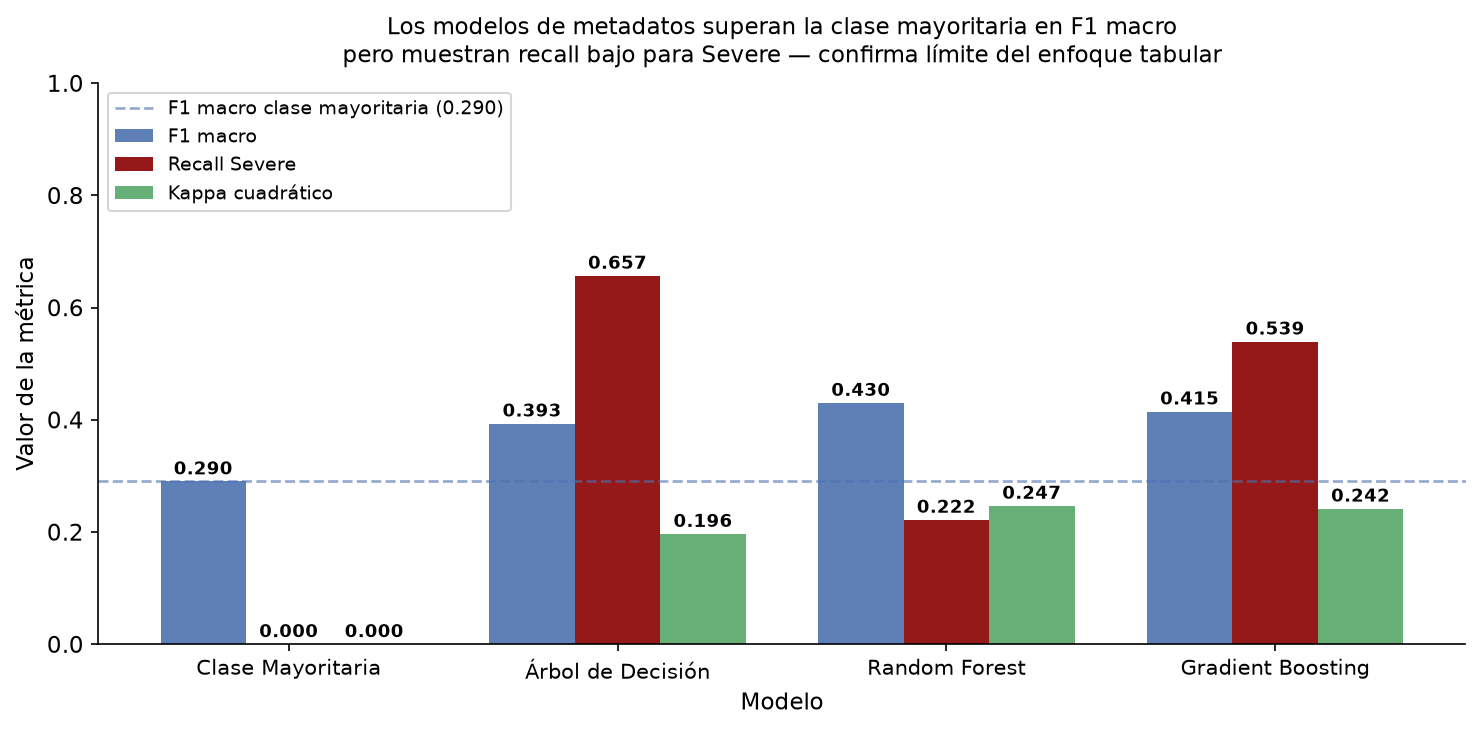

 Guardada: figures/fig1_f1_recall_kappa_por_modelo.png


In [15]:
# ── Figura 1: F1 macro y Recall Severe por modelo ──
model_names  = ["Clase Mayoritaria", "Árbol de Decisión", "Random Forest", "Gradient Boosting"]
f1_macros    = [res_dummy["f1_macro"],    res_dt["f1_macro"],    res_rf["f1_macro"],    res_gb["f1_macro"]]
recall_sev   = [res_dummy["recall_severe"],res_dt["recall_severe"],res_rf["recall_severe"],res_gb["recall_severe"]]
kappas       = [res_dummy["kappa_quadratic"],res_dt["kappa_quadratic"],res_rf["kappa_quadratic"],res_gb["kappa_quadratic"]]

x_pos = np.arange(len(model_names))
w = 0.26

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x_pos - w, f1_macros,  w, label="F1 macro",     color="#4C72B0", alpha=0.9)
bars2 = ax.bar(x_pos,     recall_sev, w, label="Recall Severe", color="#8B0000", alpha=0.9)
bars3 = ax.bar(x_pos + w, kappas,     w, label="Kappa cuadrático", color="#55A868", alpha=0.9)

for bars in [bars1, bars2, bars3]:
    for b in bars:
        h = b.get_height()
        ax.text(b.get_x() + b.get_width()/2, h + 0.005, f"{h:.3f}",
                ha="center", va="bottom", fontsize=8.5, fontweight="bold")

ax.axhline(y=res_dummy["f1_macro"], color="#4C72B0", linestyle="--", lw=1.3,
           label=f"F1 macro clase mayoritaria ({res_dummy['f1_macro']:.3f})", alpha=0.6)

ax.set_xticks(x_pos)
ax.set_xticklabels(model_names, fontsize=10)
ax.set_ylim(0, 1.0)
ax.set_ylabel("Valor de la métrica", fontsize=11)
ax.set_title(
    "Los modelos de metadatos superan la clase mayoritaria en F1 macro\n"
    "pero muestran recall bajo para Severe — confirma límite del enfoque tabular",
    fontsize=11, pad=10
)
ax.legend(fontsize=9, loc="upper left")
ax.set_xlabel("Modelo", fontsize=11)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig(FIG / "fig1_f1_recall_kappa_por_modelo.png", dpi=300, bbox_inches="tight")
plt.show()
print(" Guardada: figures/fig1_f1_recall_kappa_por_modelo.png")


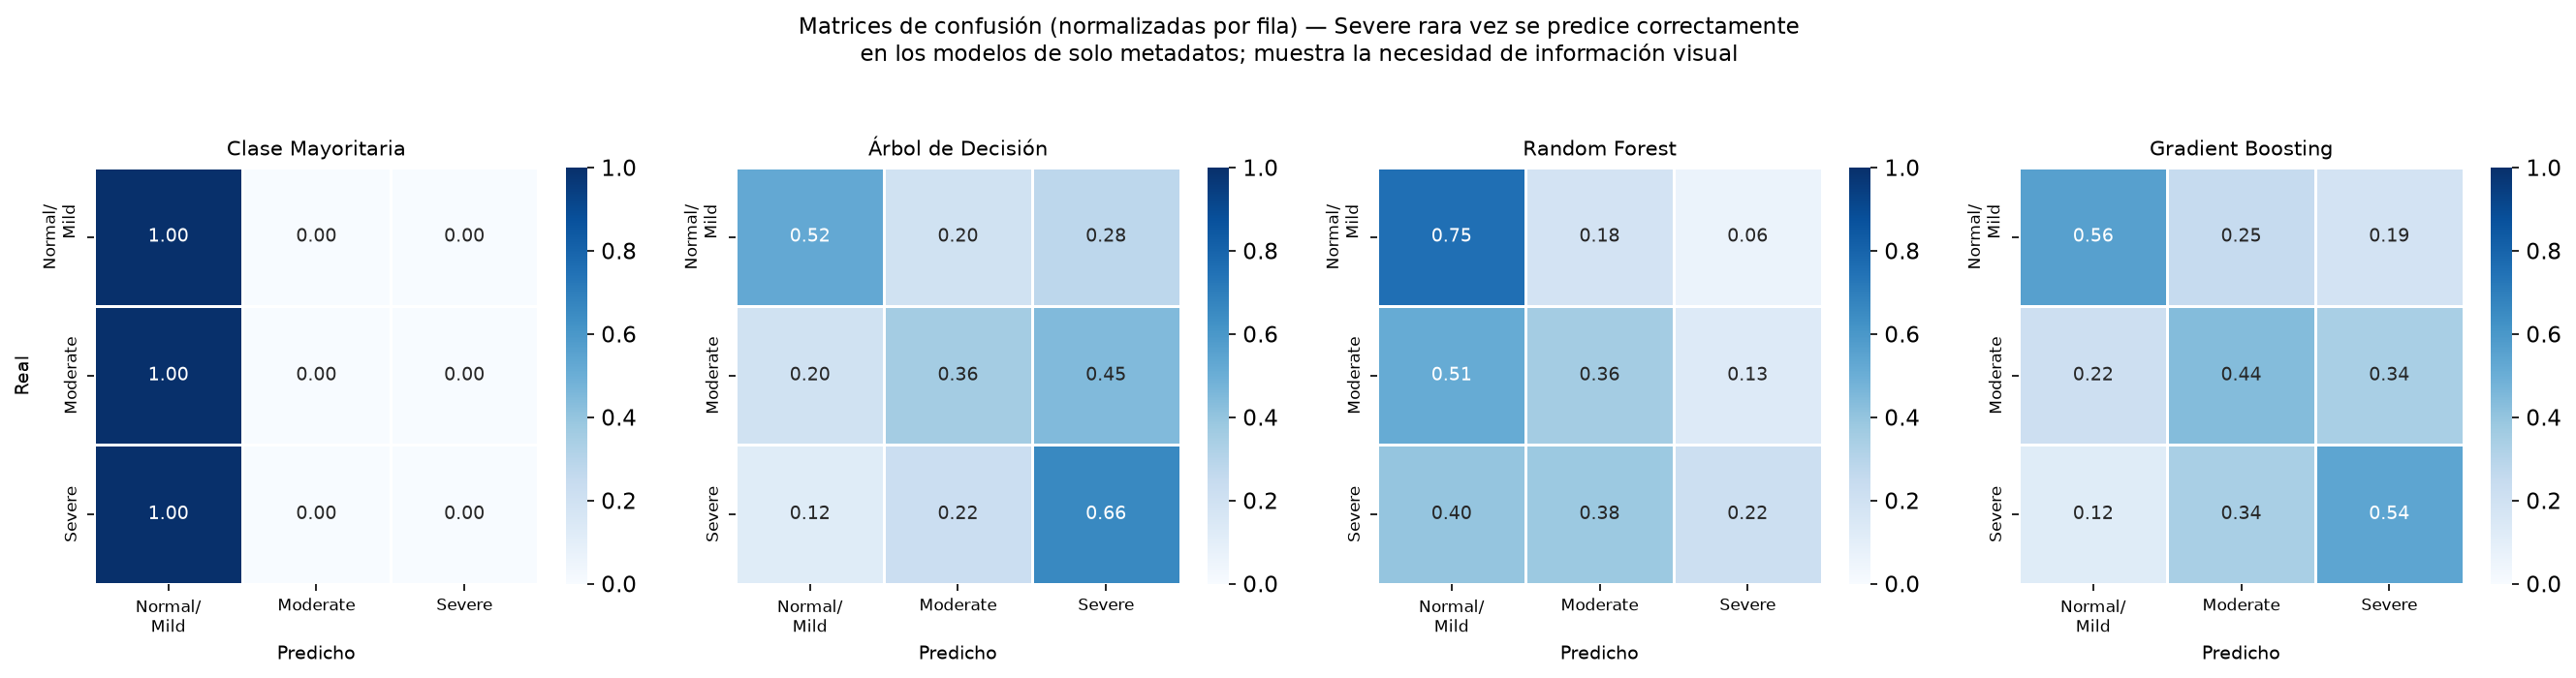

 Guardada: figures/fig2_matrices_confusion.png


In [16]:
# ── Figura 2: Matrices de confusión normalizadas por fila ──
modelos_plot = [
    ("Clase Mayoritaria", res_dummy["confusion_matrix"]),
    ("Árbol de Decisión", res_dt["confusion_matrix"]),
    ("Random Forest",     res_rf["confusion_matrix"]),
    ("Gradient Boosting", res_gb["confusion_matrix"]),
]

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
tick_labels = ["Normal/\nMild", "Moderate", "Severe"]

for ax, (nombre, cm_raw) in zip(axes, modelos_plot):
    cm = np.array(cm_raw, dtype=float)
    cm_norm = cm / (cm.sum(axis=1, keepdims=True) + 1e-9)
    sns.heatmap(
        cm_norm, annot=True, fmt=".2f",
        xticklabels=tick_labels, yticklabels=tick_labels,
        cmap="Blues", ax=ax, vmin=0, vmax=1, linewidths=0.5,
        annot_kws={"size": 9}
    )
    ax.set_title(nombre, fontsize=10, pad=6)
    ax.set_ylabel("Real" if ax is axes[0] else "", fontsize=9)
    ax.set_xlabel("Predicho", fontsize=9)
    ax.tick_params(axis="both", labelsize=8)

fig.suptitle(
    "Matrices de confusión (normalizadas por fila) — Severe rara vez se predice correctamente\n"
    "en los modelos de solo metadatos; muestra la necesidad de información visual",
    fontsize=11, y=1.03
)
plt.tight_layout()
plt.savefig(FIG / "fig2_matrices_confusion.png", dpi=300, bbox_inches="tight")
plt.show()
print(" Guardada: figures/fig2_matrices_confusion.png")


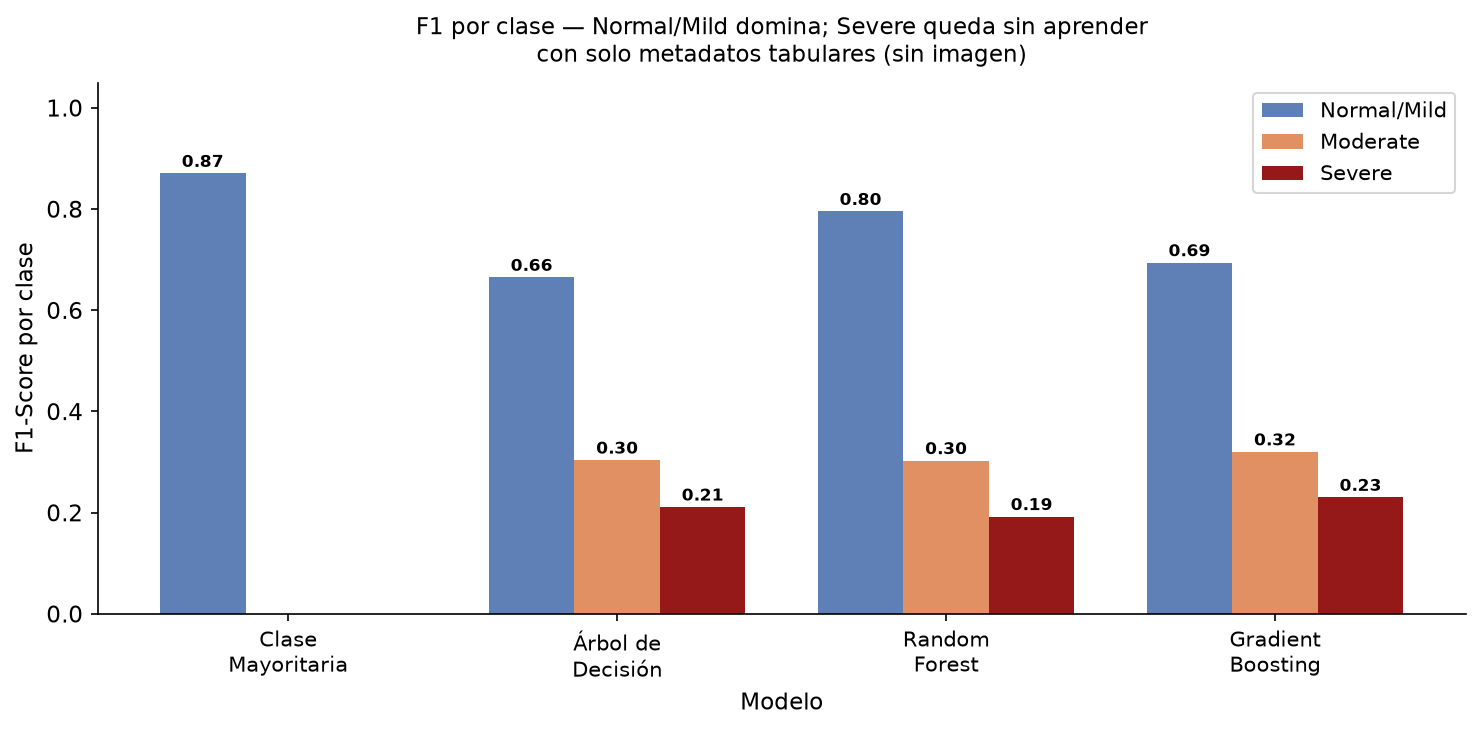

 Guardada: figures/fig3_f1_por_clase_y_modelo.png


In [17]:
# ── Figura 3: F1 por clase para cada modelo ──
modelos_f1 = {
    "Clase\nMayoritaria": res_dummy["f1_per_class"],
    "Árbol de\nDecisión": res_dt["f1_per_class"],
    "Random\nForest":    res_rf["f1_per_class"],
    "Gradient\nBoosting":res_gb["f1_per_class"],
}

x_pos = np.arange(len(modelos_f1))
w = 0.26
nombres = list(modelos_f1.keys())
f1_nm  = [v[0] for v in modelos_f1.values()]
f1_mod = [v[1] for v in modelos_f1.values()]
f1_sev = [v[2] for v in modelos_f1.values()]

fig, ax = plt.subplots(figsize=(10, 5))
b1 = ax.bar(x_pos - w, f1_nm,  w, label="Normal/Mild", color=PAL["Normal/Mild"], alpha=0.9)
b2 = ax.bar(x_pos,     f1_mod, w, label="Moderate",    color=PAL["Moderate"],    alpha=0.9)
b3 = ax.bar(x_pos + w, f1_sev, w, label="Severe",      color=PAL["Severe"],      alpha=0.9)

for bars in [b1, b2, b3]:
    for b in bars:
        h = b.get_height()
        if h > 0.01:
            ax.text(b.get_x() + b.get_width()/2, h + 0.005, f"{h:.2f}",
                    ha="center", va="bottom", fontsize=8, fontweight="bold")

ax.set_xticks(x_pos)
ax.set_xticklabels(nombres, fontsize=10)
ax.set_ylim(0, 1.05)
ax.set_ylabel("F1-Score por clase", fontsize=11)
ax.set_xlabel("Modelo", fontsize=11)
ax.set_title(
    "F1 por clase — Normal/Mild domina; Severe queda sin aprender\n"
    "con solo metadatos tabulares (sin imagen)",
    fontsize=11, pad=10
)
ax.legend(fontsize=10)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig(FIG / "fig3_f1_por_clase_y_modelo.png", dpi=300, bbox_inches="tight")
plt.show()
print(" Guardada: figures/fig3_f1_por_clase_y_modelo.png")


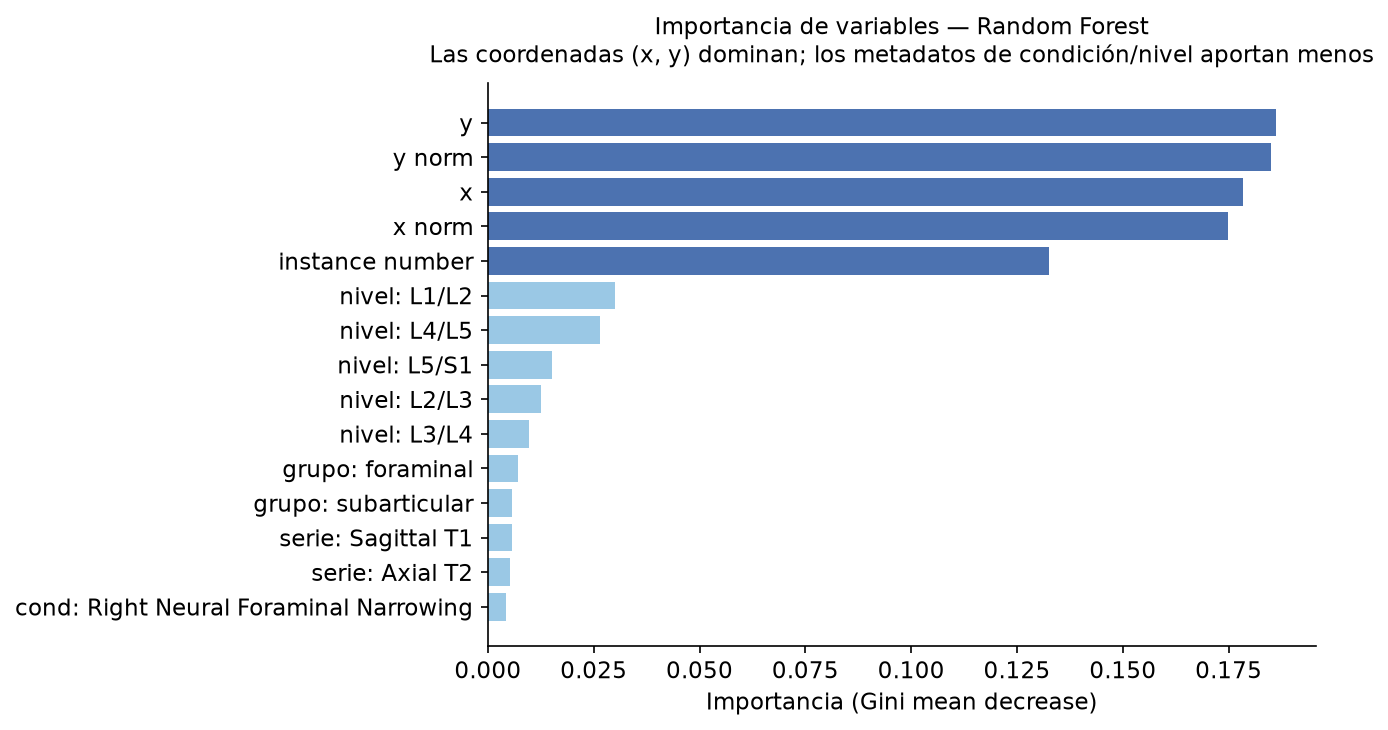

 Guardada: figures/fig4_importancia_variables_rf.png


In [18]:
# ── Figura 4: Top 15 importancias de variables (Random Forest) ──
importances = pd.Series(rf_final.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False).head(15)

# Etiquetas más legibles
etiquetas = (
    importances.index
    .str.replace("condition_", "cond: ", regex=False)
    .str.replace("level_", "nivel: ", regex=False)
    .str.replace("series_description_", "serie: ", regex=False)
    .str.replace("grupo_", "grupo: ", regex=False)
    .str.replace("_", " ", regex=False)
)

fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#4C72B0" if i < 5 else "#9AC8E5" for i in range(len(importances))]
ax.barh(etiquetas[::-1], importances.values[::-1], color=colors[::-1])
ax.set_xlabel("Importancia (Gini mean decrease)", fontsize=11)
ax.set_title(
    "Importancia de variables — Random Forest\n"
    "Las coordenadas (x, y) dominan; los metadatos de condición/nivel aportan menos",
    fontsize=11, pad=10
)
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig(FIG / "fig4_importancia_variables_rf.png", dpi=300, bbox_inches="tight")
plt.show()
print(" Guardada: figures/fig4_importancia_variables_rf.png")


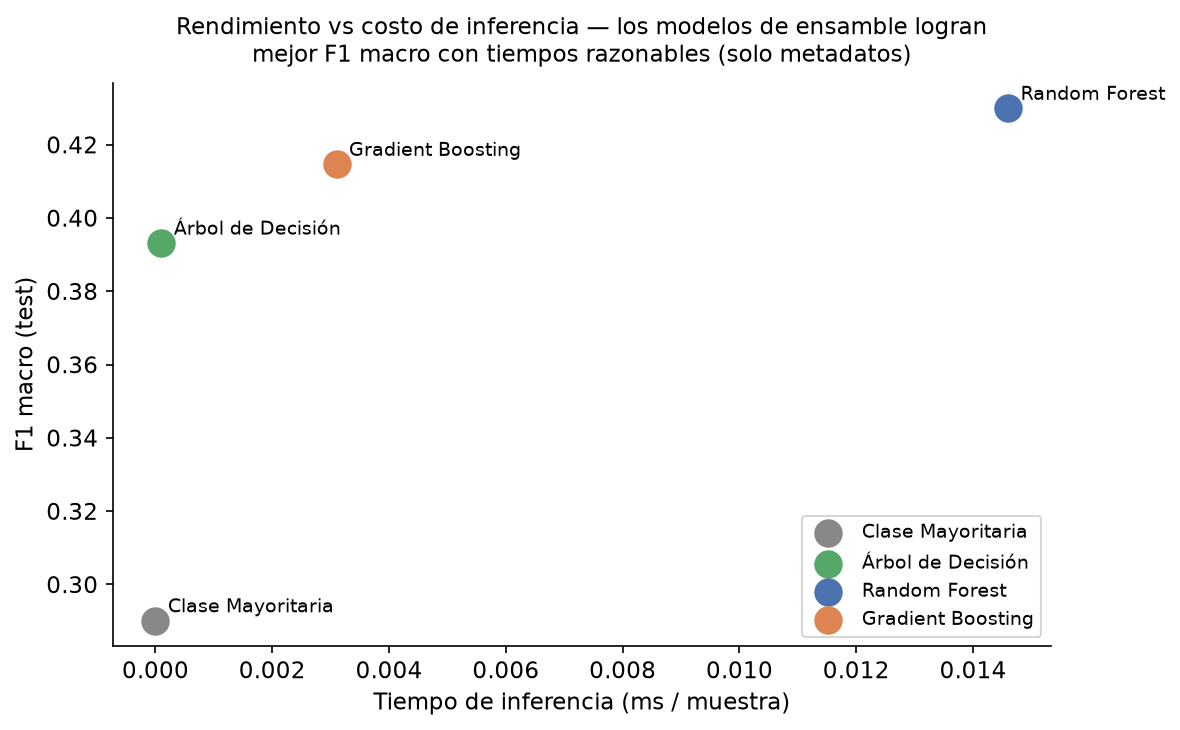

 Guardada: figures/fig5_tiempo_vs_rendimiento.png


In [19]:
# ── Figura 5: Tiempo de inferencia vs F1 macro ──
modelos_costos = [
    ("Clase Mayoritaria", res_dummy),
    ("Árbol de Decisión", res_dt),
    ("Random Forest",     res_rf),
    ("Gradient Boosting", res_gb),
]

nombres_c   = [m[0] for m in modelos_costos]
f1s_c       = [m[1]["f1_macro"] for m in modelos_costos]
t_infer_ms  = [
    (m[1]["t_infer_ms_per_sample"] or 0.0) for m in modelos_costos
]

fig, ax = plt.subplots(figsize=(8, 5))
scatter_colors = ["#888888", "#55A868", "#4C72B0", "#DD8452"]
for i, (nom, f1, t) in enumerate(zip(nombres_c, f1s_c, t_infer_ms)):
    ax.scatter(t, f1, s=160, color=scatter_colors[i], zorder=5, label=nom)
    ax.annotate(nom, (t, f1), textcoords="offset points", xytext=(6, 4), fontsize=9)

ax.set_xlabel("Tiempo de inferencia (ms / muestra)", fontsize=11)
ax.set_ylabel("F1 macro (test)", fontsize=11)
ax.set_title(
    "Rendimiento vs costo de inferencia — los modelos de ensamble logran\n"
    "mejor F1 macro con tiempos razonables (solo metadatos)",
    fontsize=11, pad=10
)
ax.legend(fontsize=9, loc="lower right")
sns.despine(ax=ax)
plt.tight_layout()
plt.savefig(FIG / "fig5_tiempo_vs_rendimiento.png", dpi=300, bbox_inches="tight")
plt.show()
print(" Guardada: figures/fig5_tiempo_vs_rendimiento.png")


## 12. Reporte de comparación y discusión (Fase E)

In [20]:
print("=" * 70)
print("COMPARACIÓN FINAL — TEST SET (línea base metadatos, sin imagen)")
print("=" * 70)
header = f"{'Modelo':<22} {'F1 macro':>10} {'Rec. Sev':>10} {'Bal.Acc':>9} {'Kappa Q':>9} {'LogL RSNA':>11}"
print(header)
print("-" * 70)
for r in [res_dummy, res_dt, res_rf, res_gb]:
    ll = f"{r['log_loss_rsna']:.4f}" if r['log_loss_rsna'] else "  N/A  "
    print(
        f"{r['modelo']:<22} {r['f1_macro']:>10.4f} "
        f"{r['recall_severe']:>10.4f} {r['balanced_accuracy']:>9.4f} "
        f"{r['kappa_quadratic']:>9.4f} {ll:>11}"
    )


COMPARACIÓN FINAL — TEST SET (línea base metadatos, sin imagen)
Modelo                   F1 macro   Rec. Sev   Bal.Acc   Kappa Q   LogL RSNA
----------------------------------------------------------------------
Clase_Mayoritaria          0.2901     0.0000    0.3333    0.0000      1.3498
Arbol_Decision             0.3932     0.6566    0.5124    0.1965      0.1887
Random_Forest              0.4300     0.2217    0.4442    0.2466      0.1972
Gradient_Boosting          0.4147     0.5393    0.5133    0.2416      0.1811
